# Libraries

In [1]:
# Standard
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Science
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

# Dataset

In [2]:
df_raw = pd.read_csv("processed_data/encoded.csv")

In [3]:
features_individual = ['sex', 'age']
features_school = ['failures', 'school', 'studytime']
features_family = ['Medu', 'Fedu', 'address', 'internet']
features_external = ['higher', 'Dalc', 'reason_reputation']

In [4]:
df = df_raw.copy()
independent_variables = features_individual + features_school + features_family
dependent_variable = ["G3"]
df = df[independent_variables + dependent_variable]

# Leaving out outliers

Given the results of Simple Linear Regression, only people who quit (G3 results = 0 or 1) will be considered outliers, since they did not perform the test or did not even study, altering the dataset.

In [5]:
print(df.shape)
df = df.loc[~(df_raw["G3"] <= 1)]
print(df.shape)

(649, 10)
(633, 10)


A logistic regression will be attempted in order to predict the probability of a student quitting

# Regression

In [6]:
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.264
Model:                            OLS   Adj. R-squared:                  0.253
Method:                 Least Squares   F-statistic:                     24.83
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           1.56e-36
Time:                        21:19:04   Log-Likelihood:                -1419.2
No. Observations:                 633   AIC:                             2858.
Df Residuals:                     623   BIC:                             2903.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.8736      1.377      5.717      0.0

* R-squared = *fraction of the variability of y explained by x*
    * 26% of variability explained    
    * improved with respect to previous model (23%)
* Adjusted R-squared = *accounts for the number of independent variables. In simple linear regression, it is very similar to R-squared*
    * 26% of variability explained    
    * improved with respect to previous model (22%)
* Prob (F-statistic) = *accounts for the statistical significativity of the model in its entirety. Null Hypothesis $H_0$ : model not significant*
    * close to 0, so statistically significant model even if with low variance explained
* P>|t| = *p-value of the coefficient, with the Null Hypothesis $H_0 : coef = 0$. When lower than 0.05, the coefficient is considered statistically significant*
    * Reject $H_0$ for all previous coefficients
    * Reject $H_0$ for Medu
    * Failed to reject $H_0$ for all other new coefficients

This time, to compare the relative importance of correlation coefficients, it is important to calculate standardized coefficients $\beta$.\
These coefficient indicate how much Y varies when X increases of 1 standard deviation

In [7]:
std_y = y.std()
std_x = df[independent_variables].std()

beta = model.params[independent_variables] * std_x / std_y

coefficients = pd.DataFrame({
    "B": model.params[independent_variables],
    "Beta": beta,
    "P-value": model.pvalues[independent_variables]
})

print(coefficients.sort_values(
    "Beta",
    key=abs,
    ascending=False
))

                  B      Beta       P-value
failures  -1.536739 -0.334907  1.751657e-18
Medu       0.418232  0.178429  1.586577e-04
studytime  0.468510  0.146940  4.710727e-05
school    -0.716835 -0.127437  8.947663e-04
sex       -0.580729 -0.107424  2.790498e-03
age        0.177834  0.081260  2.591483e-02
internet   0.162080  0.025594  4.823777e-01
address   -0.122636 -0.021075  5.689214e-01
Fedu       0.043000  0.017840  6.935743e-01


So: 
* Medu is significant, while the other 3 new coefficients are not 

The multicollinearity (how much independent variables are correlated) has also to be analyzed:
* VIF = 1 -> *no relevant issues*
* 1 < VIF < 5 -> *acceptable*
* VIF > 5 -> *attention*
* VIF > 10 -> *important multicollinearity*

In [8]:
vif = pd.DataFrame()

vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif)

    Variable         VIF
0      const  227.767287
1        sex    1.084005
2        age    1.121143
3   failures    1.158195
4     school    1.233931
5  studytime    1.088106
6       Medu    1.865932
7       Fedu    1.733697
8    address    1.157446
9   internet    1.122255


Med and Fedu are correlated to each other (acceptable)

## Checking assumptions

Resuming all assumptions:
* linearity
    * graph of residuals -> not a good shape
* independence of errors (Durbin-Watson) -> OK
* homoscedasticity (equally dispersed)
    * graph -> many high values
    * Breusch-Pagan -> heteroscedastic
* normally distributed -> violated
    * Q-Q plot
    * Shapiro-Wilk

### Residuals

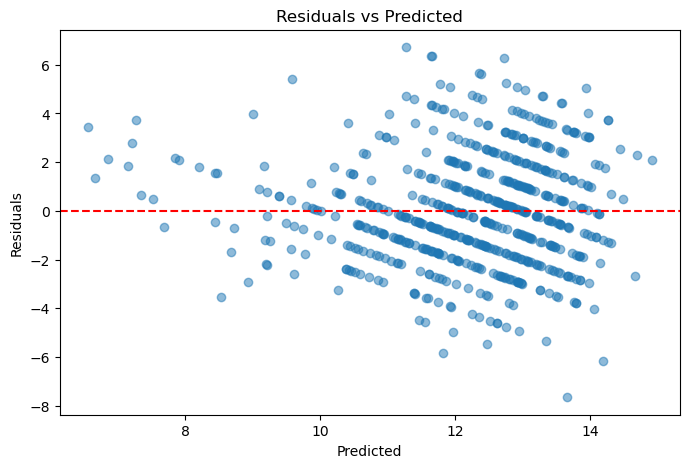

In [9]:
residuals = model.resid
predicted = model.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(predicted, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

I can check residuals of every single variable

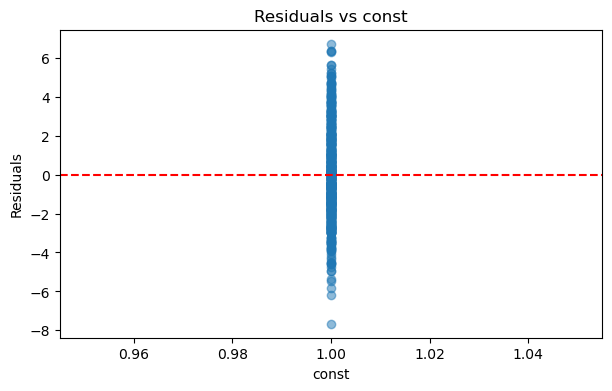

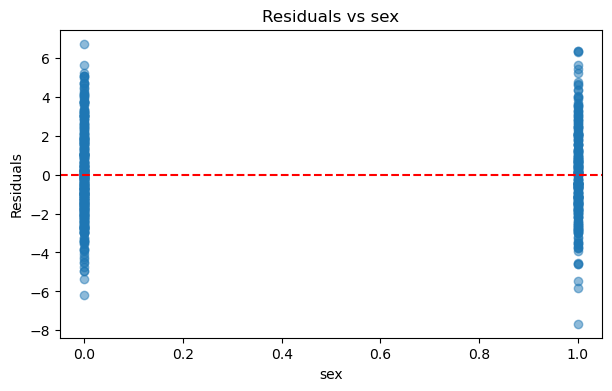

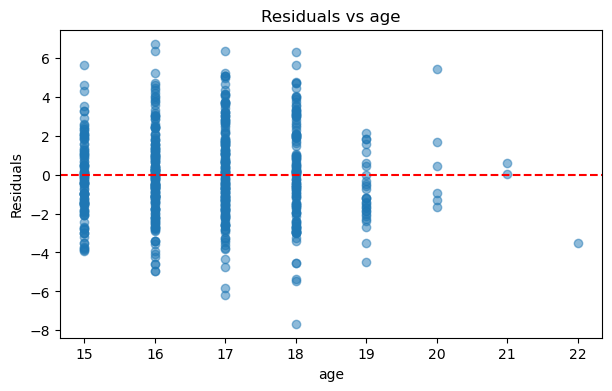

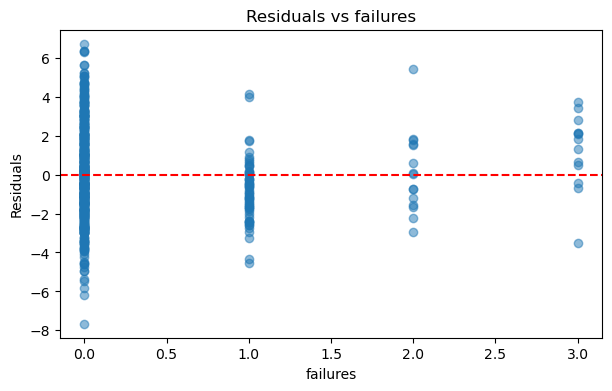

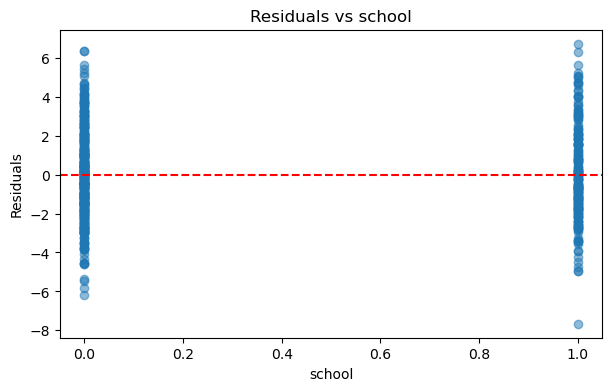

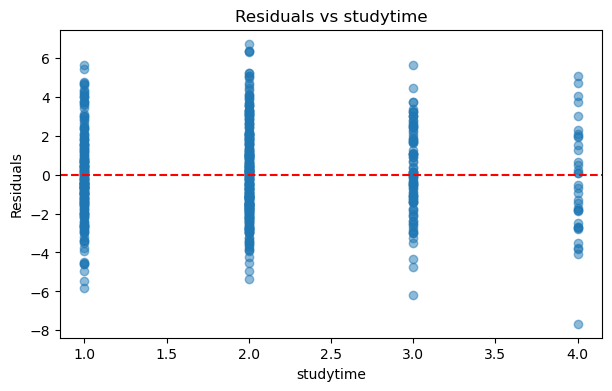

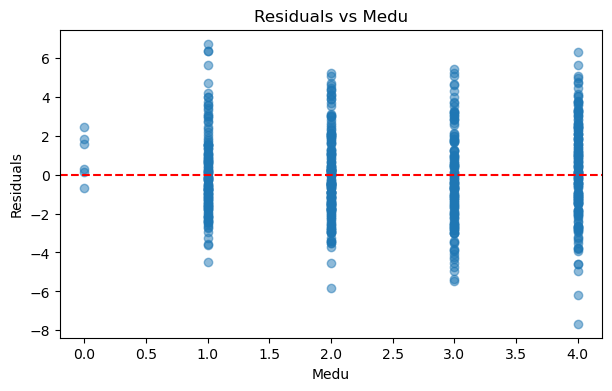

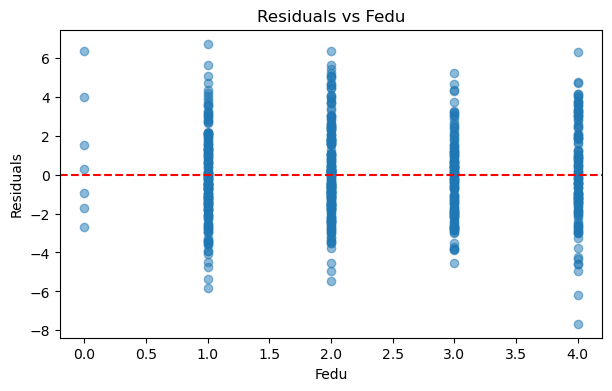

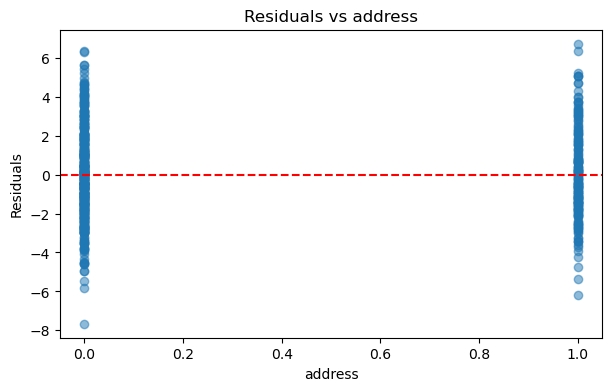

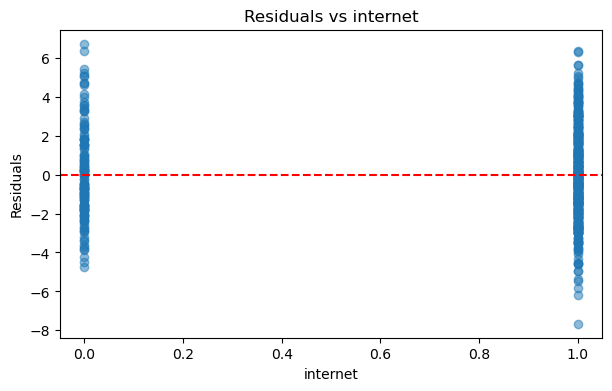

In [10]:
for col in X.columns:
    plt.figure(figsize=(7,4))
    plt.scatter(X[col], residuals, alpha=0.5)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel(col)
    plt.ylabel('Residuals')
    plt.title(f'Residuals vs {col}')
    plt.show()

### Independence of errors

Durbin-Watson = (1.72) -> no autocorrelation

### Homoscedasticity

In [11]:
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

labels = ['LM Statistic', 'LM p-value',
          'F Statistic', 'F p-value']

print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(24.45964727242724), 'LM p-value': np.float64(0.003630820745478439), 'F Statistic': np.float64(2.782315308064882), 'F p-value': np.float64(0.003336463389921744)}


Data are still heteroscedastic.

Even with the robust regression, nothing changes

In [12]:
model_robust = model.get_robustcov_results(
    cov_type='HC3'
)

print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.264
Model:                            OLS   Adj. R-squared:                  0.253
Method:                 Least Squares   F-statistic:                     27.69
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           1.81e-40
Time:                        21:19:06   Log-Likelihood:                -1419.2
No. Observations:                 633   AIC:                             2858.
Df Residuals:                     623   BIC:                             2903.
Df Model:                           9                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.8736      1.371      5.743      0.0

### Normality of residuals

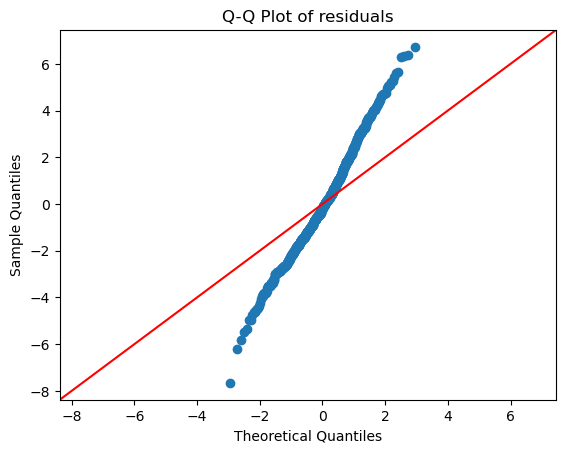

In [13]:
sm.qqplot(residuals, line='45')
plt.title('Q-Q Plot of residuals')
plt.show()

Shapiro-Wilk test
* $H_0$ : Residuals follow a normal distribution
* $H_1$ : Residuals DO NOT follow a normal distribution

In [14]:
stat, p_value = shapiro(model.resid)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 0.9930673416181943
P-value: 0.0050205874341209015


Again, the assumption of normality of residuals is violated

* Estimate of coefficients and errors are separate concepts
* alongside the normality of residuals, the distribution of estimated of coefficients with a large sample (N = 633) is also important
* with the central limit theorem, the distribution of coefficients can be approximated as normal even if individual errors are not normally distributed, because the estimate of coefficients becomes more accurate with large datasets 

## Candidate outliers

In [15]:
infl = model.get_influence()

df['standardized_residuals'] = (
    infl.resid_studentized_internal
)

outlier = df[
    np.abs(df['standardized_residuals']) > 3
]

print(outlier)

     sex  age  failures  school  studytime  Medu  Fedu  address  internet  G3  \
523    1   18         0       1          4     4     4        0         1   6   

     standardized_residuals  
523                -3.38813  


## Influence

In [16]:
influence = model.get_influence()

cooks_distance = influence.cooks_distance[0]

df['cooks_distance'] = cooks_distance

print(
    df.sort_values(
        'cooks_distance',
        ascending=False
    ).head(10)
)

     sex  age  failures  school  studytime  Medu  Fedu  address  internet  G3  \
523    1   18         0       1          4     4     4        0         1   6   
351    1   20         2       0          1     3     2        0         0  15   
279    1   22         3       0          1     3     1        0         1   5   
314    1   17         0       0          2     1     2        1         0  18   
170    0   18         3       0          1     1     1        1         0  11   
338    0   17         0       0          4     3     1        1         0  19   
636    1   18         0       1          2     4     4        0         1  19   
169    1   17         3       0          1     1     2        1         0  10   
185    1   16         0       0          2     1     0        0         1  18   
327    0   18         0       0          4     1     1        1         0  18   

     standardized_residuals  cooks_distance  
523               -3.388130        0.036317  
351             

In [17]:
cooks_threshold = 4 / len(df)
print(cooks_threshold)

0.00631911532385466


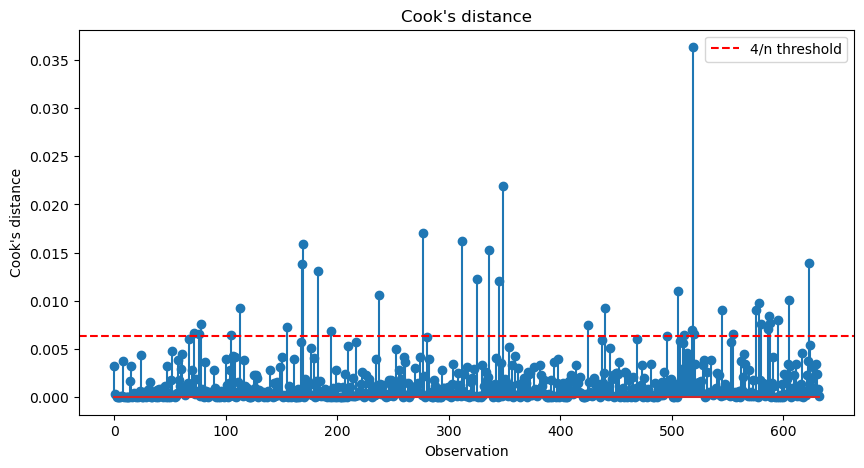

In [18]:
plt.figure(figsize=(10, 5))

plt.stem(
    np.arange(len(df)),
    df['cooks_distance']
)

plt.axhline(
    cooks_threshold,
    color='red',
    linestyle='--',
    label='4/n threshold'
)

plt.xlabel('Observation')
plt.ylabel("Cook's distance")
plt.title("Cook's distance")
plt.legend()
plt.show()

# RMSE and MAE

They will be calculated:
* in-sample = *on the sample used to estimate the regression*
    * evaluates how well the model describes the data
    * measuring the adaptament error
* out-of-sample = *on a test sub-set*
    * evaluates how well the model can generalize on new data
    * measuring the predictive capability

In [19]:
y_pred = model.predict(X)

mae_in = mean_absolute_error(y, y_pred)
rmse_in = np.sqrt(mean_squared_error(y, y_pred))

print("MAE in-sample:", round(mae_in, 3))
print("RMSE in-sample:", round(rmse_in, 3))

MAE in-sample: 1.819
RMSE in-sample: 2.278


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

model_train = sm.OLS(y_train, X_train).fit()

y_pred_test = model_train.predict(X_test)

mae_out = mean_absolute_error(y_test, y_pred_test)
rmse_out = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("MAE out-of-sample:", round(mae_out, 3))
print("RMSE out-of-sample:", round(rmse_out, 3))

MAE out-of-sample: 1.838
RMSE out-of-sample: 2.244


In [21]:
results = pd.DataFrame({
    'MAE': [mae_in, mae_out],
    'RMSE': [rmse_in, rmse_out]
}, index=['In-sample', 'Out-of-sample'])

display(round(results, 3))

,MAE,RMSE
In-sample,1.819,2.278
Out-of-sample,1.838,2.244


* In-sample and out-of-sample values are similar = the model has stable predictive capability
* When RMSE is a lot higher than MAE, there could be some high prediction errors

For the ratio between in-sample and out-of-sample.

$\delta$% = $\frac{OOS - IS}{IS} * 100$

where OOS = Out-of-sample, IS = In-sample

| $\delta$%        | Indicative interpretation       |
|------------------|---------------------------------|
| 0 - 5            | Optimal stability               |
| 5 - 10           | Good stability                  |
| 10 - 20          | Possible overfitting            |
| 20 - 30          | Likely overfitting              |
| > 30             | Significant overfitting         |

| Ratio RMSE / MAE | Indicative interpretation       |
|------------------|---------------------------------|
| 1.00 - 1.10      | Homogeneous errors              |
| 1.10 - 1.25      | Possible large errors           |
| 1.25 - 1.50      | Some large errors               |
| 1.50 - 2.00      | Very large errors               |
| > 2              | Large influence of large errors |

In [22]:
print("delta MAE:",
      round((mae_out - mae_in) / mae_in * 100, 2)
)
print("delta RMSE:",
      round((rmse_out - rmse_in) / rmse_in * 100, 2)
)

print("Ratio RMSE/MAE in-sample:",
      round(rmse_in / mae_in, 2)
)

print("Ratio RMSE/MAE out-of-sample:",
      round(rmse_out / mae_out, 2)
)

delta MAE: 1.03
delta RMSE: -1.45
Ratio RMSE/MAE in-sample: 1.25
Ratio RMSE/MAE out-of-sample: 1.22


Optimal stability but possible large errors

To check large errors

MAE: 1.837501249289414
90° percentile: 3.620338363800397
95° percentile: 4.386222880482249
Max error: 6.000654831853602


<Axes: ylabel='Count'>

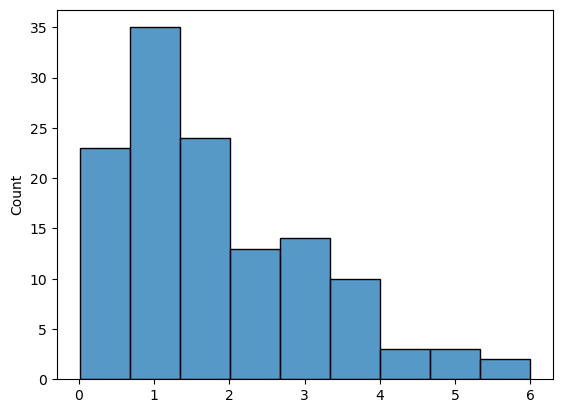

In [23]:
errors = np.abs(y_test - y_pred_test)

print("MAE:", errors.mean())
print("90° percentile:", np.percentile(errors, 90))
print("95° percentile:", np.percentile(errors, 95))
print("Max error:", errors.max())
sns.histplot(errors)

# Refined model (only statistically significant variables)

Removing variables

In [24]:
features_individual = ['sex', 'age']
features_school = ['failures', 'school', 'studytime']
features_family = ['Medu']

In [25]:
df = df_raw.copy()
df = df.loc[~(df_raw["G3"] <= 1)]
independent_variables = features_individual + features_school + features_family
dependent_variable = ["G3"]
df = df[independent_variables + dependent_variable]

In [26]:
X = df[independent_variables]
y = df["G3"]

X = sm.add_constant(X)

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.263
Model:                            OLS   Adj. R-squared:                  0.256
Method:                 Least Squares   F-statistic:                     37.19
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           1.26e-38
Time:                        21:19:17   Log-Likelihood:                -1419.7
No. Observations:                 633   AIC:                             2853.
Df Residuals:                     626   BIC:                             2885.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.8971      1.362      5.798      0.0

In [27]:
std_y = y.std()
std_x = df[independent_variables].std()

beta = model.params[independent_variables] * std_x / std_y

coefficients = pd.DataFrame({
    "B": model.params[independent_variables],
    "Beta": beta,
    "P-value": model.pvalues[independent_variables]
})

print(coefficients.sort_values(
    "Beta",
    key=abs,
    ascending=False
))

                  B      Beta       P-value
failures  -1.547134 -0.337172  7.631920e-19
Medu       0.463205  0.197616  7.522682e-08
studytime  0.466020  0.146159  4.971796e-05
school    -0.781949 -0.139013  1.212121e-04
sex       -0.576786 -0.106695  2.912455e-03
age        0.182564  0.083421  2.146572e-02


In [28]:
vif = pd.DataFrame()

vif["Variable"] = X.columns
vif["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif)

    Variable         VIF
0      const  223.524443
1        sex    1.082239
2        age    1.111739
3   failures    1.151807
4     school    1.096750
5  studytime    1.086808
6       Medu    1.119213


## Checking assumptions

### Residuals

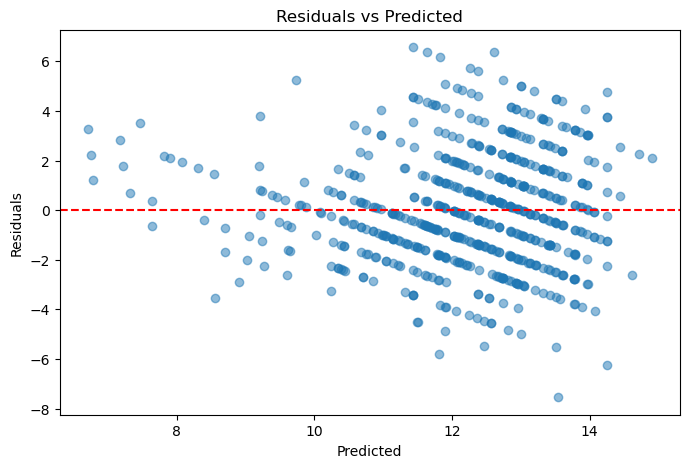

In [29]:
residuals = model.resid
predicted = model.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(predicted, residuals, alpha=0.5)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')
plt.show()

### Independence of errors

In [30]:
dw = durbin_watson(model.resid)

print(f"Durbin-Watson: {dw:.2f}")

Durbin-Watson: 1.72


### Homoscedasticity

In [31]:
bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

labels = ['LM Statistic', 'LM p-value',
          'F Statistic', 'F p-value']

print(dict(zip(labels, bp_test)))

{'LM Statistic': np.float64(22.660302300613033), 'LM p-value': np.float64(0.0009186115788192479), 'F Statistic': np.float64(3.873621332965335), 'F p-value': np.float64(0.0008330222436001332)}


Data are still heteroscedastic.

Even with the robust regression, nothing changes

In [32]:
model_robust = model.get_robustcov_results(
    cov_type='HC3'
)

print(model_robust.summary())

                            OLS Regression Results                            
Dep. Variable:                     G3   R-squared:                       0.263
Model:                            OLS   Adj. R-squared:                  0.256
Method:                 Least Squares   F-statistic:                     42.22
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           2.67e-43
Time:                        21:19:36   Log-Likelihood:                -1419.7
No. Observations:                 633   AIC:                             2853.
Df Residuals:                     626   BIC:                             2885.
Df Model:                           6                                         
Covariance Type:                  HC3                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          7.8971      1.353      5.835      0.0

### Normality of residuals

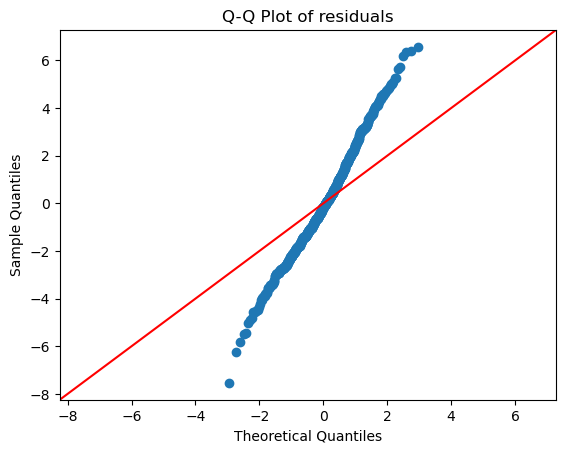

In [33]:
sm.qqplot(residuals, line='45')
plt.title('Q-Q Plot of residuals')
plt.show()

Shapiro-Wilk test
* $H_0$ : Residuals follow a normal distribution
* $H_1$ : Residuals DO NOT follow a normal distribution

In [34]:
stat, p_value = shapiro(model.resid)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 0.9933148833795159
P-value: 0.006457816327538002


Again, the assumption of normality of residuals is violated

# Conclusions

> Model

The `model cannot predict if a student will quit`.\
The model predicts the effects on final grade by:
* sex = *males have a lower score (almost 0.6 points)*
* age = *older student will have a higher score (almost 0.2 points/year increase)*
* failures = *students who failed previously will have lower scores (almost 1.5 points)*
* school = *students of MS, i.e. Mousinho da Silveira will have lower scores (almost 0.8 points)*
* studytime = *student with higher studytime will perform better (almost 0.5 points per category increase)*
* Medu = *student with educated mothers will perform better (almost 0.5 points per category increase)*

## RMSE and MAE

In [35]:
y_pred = model.predict(X)

mae_in = mean_absolute_error(y, y_pred)
rmse_in = np.sqrt(mean_squared_error(y, y_pred))

print("MAE in-sample:", round(mae_in, 3))
print("RMSE in-sample:", round(rmse_in, 3))

MAE in-sample: 1.823
RMSE in-sample: 2.279


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test)

model_train = sm.OLS(y_train, X_train).fit()

y_pred_test = model_train.predict(X_test)

mae_out = mean_absolute_error(y_test, y_pred_test)
rmse_out = np.sqrt(mean_squared_error(y_test, y_pred_test))

print("MAE out-of-sample:", round(mae_out, 3))
print("RMSE out-of-sample:", round(rmse_out, 3))

MAE out-of-sample: 1.83
RMSE out-of-sample: 2.243


In [37]:
results = pd.DataFrame({
    'MAE': [mae_in, mae_out],
    'RMSE': [rmse_in, rmse_out]
}, index=['In-sample', 'Out-of-sample'])

display(round(results, 3))

,MAE,RMSE
In-sample,1.823,2.279
Out-of-sample,1.830,2.243


For the ratio between in-sample and out-of-sample.

$\delta$% = $\frac{OOS - IS}{IS} * 100$

where OOS = Out-of-sample, IS = In-sample

| $\delta$%        | Indicative interpretation       |
|------------------|---------------------------------|
| 0 - 5            | Optimal stability               |
| 5 - 10           | Good stability                  |
| 10 - 20          | Possible overfitting            |
| 20 - 30          | Likely overfitting              |
| > 30             | Significant overfitting         |

| Ratio RMSE / MAE | Indicative interpretation       |
|------------------|---------------------------------|
| 1.00 - 1.10      | Homogeneous errors              |
| 1.10 - 1.25      | Possible large errors           |
| 1.25 - 1.50      | Some large errors               |
| 1.50 - 2.00      | Very large errors               |
| > 2              | Large influence of large errors |

In [38]:
print("delta MAE:",
      round((mae_out - mae_in) / mae_in * 100, 2)
)
print("delta RMSE:",
      round((rmse_out - rmse_in) / rmse_in * 100, 2)
)

print("Ratio RMSE/MAE in-sample:",
      round(rmse_in / mae_in, 2)
)

print("Ratio RMSE/MAE out-of-sample:",
      round(rmse_out / mae_out, 2)
)

delta MAE: 0.43
delta RMSE: -1.6
Ratio RMSE/MAE in-sample: 1.25
Ratio RMSE/MAE out-of-sample: 1.23


Optimal stability but some large errors

To check large errors

MAE: 1.8303636236744447
90° percentile: 3.6205684251648718
95° percentile: 4.461686853831663
Max error: 5.976411774381342


<Axes: ylabel='Count'>

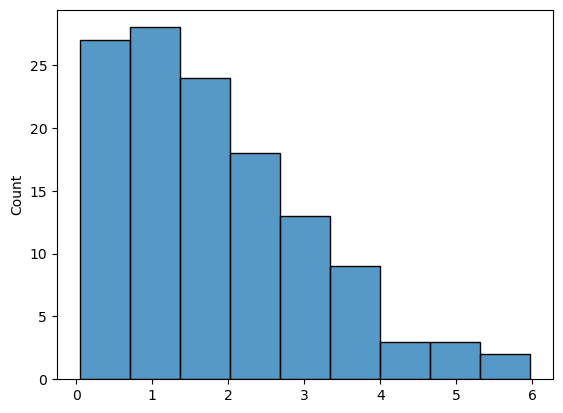

In [39]:
errors = np.abs(y_test - y_pred_test)

print("MAE:", errors.mean())
print("90° percentile:", np.percentile(errors, 90))
print("95° percentile:", np.percentile(errors, 95))
print("Max error:", errors.max())
sns.histplot(errors)